# C2: Bias-Variance Tradeoff

## Introduction

In machine learning, our goal is to build models that generalize well to new, unseen data. However, every model makes prediction errors. Understanding the sources of these errors is crucial for building effective models. The **Bias-Variance Tradeoff** is the conflict in trying to minimize two sources of error that prevent supervised learning algorithms from generalizing beyond their training set.

### The Three Sources of Error

1.  **Bias (Systematic Error)**: Error due to erroneous assumptions in the learning algorithm. High bias can cause an algorithm to miss the relevant relations between features and target outputs (**underfitting**).
    - *Example*: Fitting a straight line (linear regression) to data that clearly follows a curved path.

2.  **Variance (Sensitivity)**: Error due to sensitivity to small fluctuations in the training set. High variance can cause an algorithm to model the random noise in the training data rather than the intended outputs (**overfitting**).
    - *Example*: A highly complex polynomial that passes through every single data point, including outliers.

3.  **Irreducible Error (Noise)**: The noise in the data itself. No matter how good the model is, the data will have some noise that cannot be removed. This serves as the lower bound on the error.
    - *Example*: Measurement errors or unobserved variables affecting the potential outcome.

## 2. Mathematical Decomposition of Error

We typically measure prediction error using **Mean Squared Error (MSE)**. Let's mathematically break down the Mean Squared Error for an unseen sample $x$.

Let:
- $f(x)$ be the true function (fixed truth).
- $D$ be the training dataset (random variable, since we could have drawn a different dataset).
- $\hat{f}(x)$ be our trained model (random variable, because it depends on $D$).
- $\epsilon$ be the irreducible noise with mean 0 and variance $\sigma^2$, so $y = f(x) + \epsilon$.

The expected MSE over all possible training sets $D$ is defined as:

$$ E_D [(y - \hat{f}(x))^2] $$

Where expected value $E_D[...]$ is taken with respect to the randomness of the training set.

### Derivation

1. Expand the term inside expectation by adding and subtracting $E[\hat{f}(x)]$ (the average prediction of our model across many datasets):
   $$ (y - \hat{f}(x))^2 = ( (y - E[\hat{f}(x)]) + (E[\hat{f}(x)] - \hat{f}(x)) )^2 $$

2. Grouping and squaring:
   $$ = (y - E[\hat{f}(x)])^2 + (E[\hat{f}(x)] - \hat{f}(x))^2 + 2(y - E[\hat{f}(x)])(E[\hat{f}(x)] - \hat{f}(x)) $$

3. Apply expectation $E_D[...]$. Note that $y$ and $E[\hat{f}(x)]$ are constants w.r.t dataset variations, while $\hat{f}(x)$ varies. The cross-term simplifies to zero.

   This leaves us with:
   $$ E[(y - E[\hat{f}(x)])^2] + E[(E[\hat{f}(x)] - \hat{f}(x))^2] $$

4. Further decomposing the first part (knowing $y = f(x) + \epsilon$), we incorporate the noise term $\sigma^2$ (Irreducible Error).

   **The Final Equation:**
   $$ E[(y - \hat{f}(x))^2] = \underbrace{(f(x) - E[\hat{f}(x)])^2}_{Bias^2} + \underbrace{E[(E[\hat{f}(x)] - \hat{f}(x))^2]}_{Variance} + \underbrace{\sigma^2}_{Irreducible Error} $$

   - **Bias Squared**: The squared difference between the *average* prediction of our model and the *true* value.
   - **Variance**: The variance of the predictions around their mean. How much does the model "jump around" for different datasets?
   - **Irreducible Error**: The variance of the noise.

$$ Total Error = Bias^2 + Variance + Irreducible Error $$

## 3. Visualizing the Tradeoff (Polynomial Regression)

We will visualize this tradeoff using **Polynomial Regression**.

- **Degree 1 (Linear)**: High Bias, Low Variance (Underfitting)
- **Degree 15 (Complex)**: Low Bias, High Variance (Overfitting)
- **Degree 4 (Optimal)**: Balanced Bias and Variance

### The "Bulls-eye" Visual
![Bias Variance Bulls-eye](https://miro.medium.com/v2/resize:fit:1400/format:webp/0*4wwUExhVW14sqS8V)
*(Source: aman.ai - Bias Variance Tradeoff)*

In [3]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import make_pipeline

# Generate Synthetic Data (True function: Cosine curve)
np.random.seed(0)
n_samples = 30
degrees = [1, 4, 15]

def true_fun(X):
    return np.cos(1.5 * np.pi * X)

X = np.sort(np.random.rand(n_samples))
y = true_fun(X) + np.random.randn(n_samples) * 0.1  # Add noise

X_test = np.linspace(0, 1, 100)


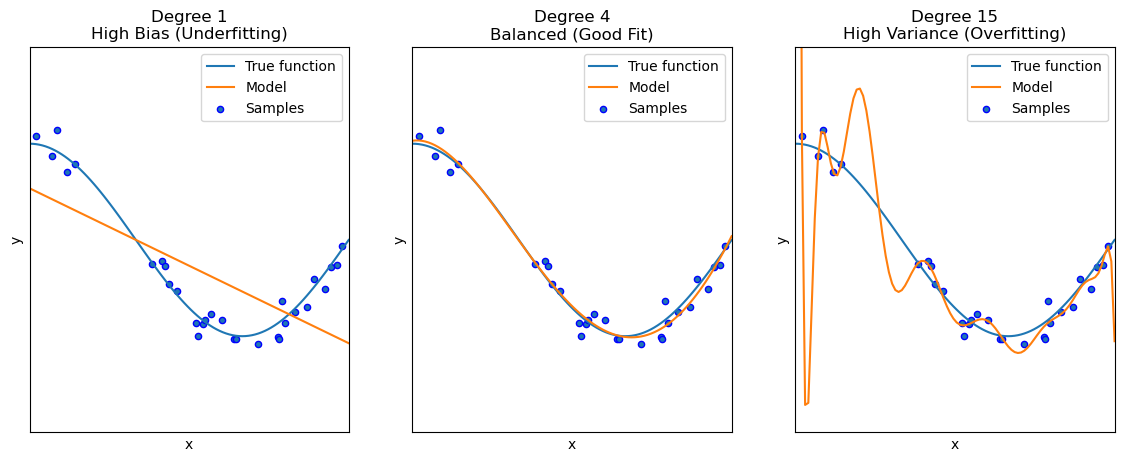

In [4]:
plt.figure(figsize=(14, 5))
for i, degree in enumerate(degrees):
    ax = plt.subplot(1, 3, i + 1)
    plt.setp(ax, xticks=(), yticks=())

    polynomial_features = PolynomialFeatures(degree=degree, include_bias=False)
    linear_regression = LinearRegression()
    pipeline = make_pipeline(polynomial_features, linear_regression)
    pipeline.fit(X[:, np.newaxis], y)

    # Evaluate
    y_pred = pipeline.predict(X_test[:, np.newaxis])
    
    plt.plot(X_test, true_fun(X_test), label="True function")
    plt.plot(X_test, y_pred, label="Model")
    plt.scatter(X, y, edgecolor='b', s=20, label="Samples")
    plt.xlabel("x")
    plt.ylabel("y")
    plt.xlim((0, 1))
    plt.ylim((-2, 2))
    plt.legend(loc="best")
    
    if degree == 1:
        plt.title(f"Degree {degree}\nHigh Bias (Underfitting)")
    elif degree == 4:
        plt.title(f"Degree {degree}\nBalanced (Good Fit)")
    else:
        plt.title(f"Degree {degree}\nHigh Variance (Overfitting)")

plt.show()

## 4. Bias Variance Evaluation Metrics

Typically, we can't calculate Bias and Variance directly on real data because we don't know the true function $f(x)$. Instead, we look at **Training Error** vs **Testing Error**.

- **High Bias (Underfitting)**: High Training Error AND High Testing Error.
- **High Variance (Overfitting)**: Low Training Error BUT High Testing Error.
- **Optimal**: Low Training Error AND Low Testing Error.

Let's plot the Error vs Complexity curve.

### Preview: Cross-Validation for Robust Evaluation

A single train/validation split can give misleading results depending on which data points end up in which set. **Cross-Validation** provides a more robust estimate of model performance by:

1. Splitting data into **K folds** (typically 5 or 10)
2. Training K times, each time using a different fold as validation
3. Averaging the results across all folds

This technique will be covered in detail in **C5: Model Tuning**. For now, we'll use a simple train/validation split to demonstrate the bias-variance tradeoff.

In [5]:
from sklearn.metrics import mean_squared_error
from sklearn.model_selection import train_test_split

# Split the data
X_train, X_val, y_train, y_val = train_test_split(X[:, np.newaxis], y, test_size=0.4, random_state=0)



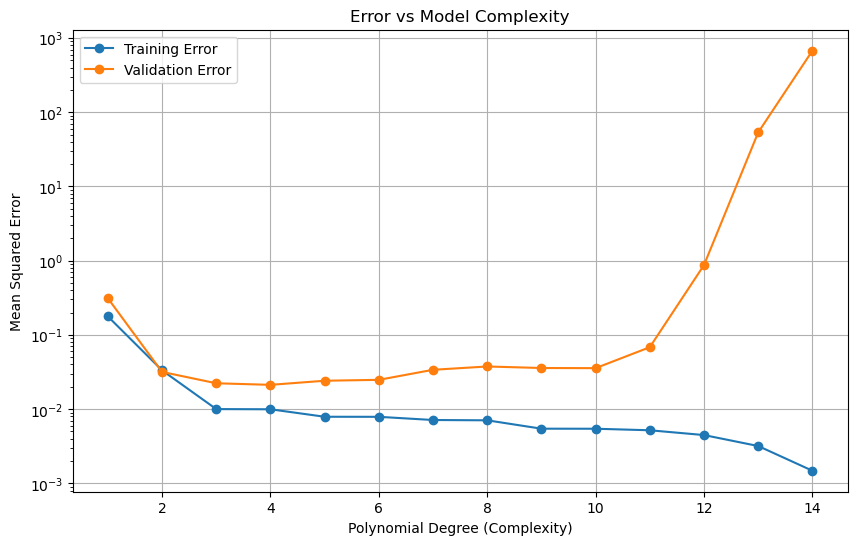

In [6]:
degrees_range = range(1, 15)
train_errors = []
val_errors = []

for d in degrees_range:
    model = make_pipeline(PolynomialFeatures(d), LinearRegression())
    model.fit(X_train, y_train)
    
    train_errors.append(mean_squared_error(y_train, model.predict(X_train)))
    val_errors.append(mean_squared_error(y_val, model.predict(X_val)))

plt.figure(figsize=(10, 6))
plt.plot(degrees_range, train_errors, label='Training Error', marker='o')
plt.plot(degrees_range, val_errors, label='Validation Error', marker='o')
plt.xlabel('Polynomial Degree (Complexity)')
plt.ylabel('Mean Squared Error')
plt.title('Error vs Model Complexity')
plt.legend()
plt.yscale('log') # Log scale to see differences better
plt.grid(True)
plt.show()

## 5. Exercise: Find the Optimal Degree

1.  Run the code below to generate a new dataset.
2.  Write a loop to test Polynomial Degrees from 1 to 10.
3.  Identify which degree gives the lowest Validation MSE.

In [ ]:
# Generate new dataset for exercise
np.random.seed(42)
X_ex = np.sort(np.random.rand(40))
y_ex = np.sin(2 * np.pi * X_ex) + np.random.randn(40) * 0.2

X_train_ex, X_test_ex, y_train_ex, y_test_ex = train_test_split(X_ex[:, np.newaxis], y_ex, test_size=0.3, random_state=42)

# TODO: Loop through degrees 1-10, train model, check MSE on X_test_ex, find best degree.